In [1]:
from PIL import Image
import numpy as np
import time

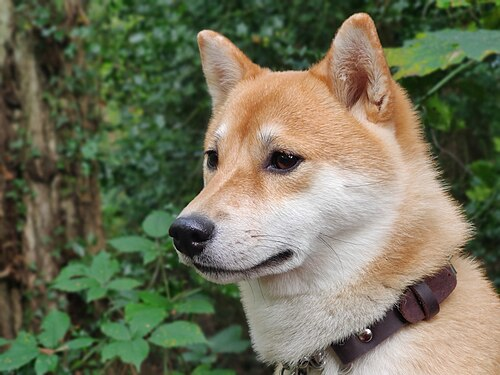

In [2]:
img = Image.open("Redshibaurajiro.jpg")
img

In [3]:
img_arr = np.array(img)
img_arr.shape

(375, 500, 3)

In [4]:
kernel = np.array(
    [
        [1,1,1],
        [0,0,0],
        [-1,-1,-1]
    ]
)

kernel.shape

(3, 3)

In [5]:
def convolution(grid,kernel):
    return (np.sum(grid * kernel,axis=0)/9).astype(np.uint8)

In [6]:
def blur(img,kernel):


    # Grid Parameter (Calculated Before Reshaping Kernel)
    n = (kernel.shape[0] - 1)

    # Converting Image into an Numpy Array for Processing
    img_arr = np.array(img,dtype=np.uint8)
    print(f"Image Dimensions : {img_arr.shape}\n")

    # Reshaping Kernel
    kernel = kernel.T.reshape(-1,1)
    print(f"Rehsaped Kernel Dimensions : {kernel.shape}")

    # Array to Store Blurred Image
    blur_img_arr = np.zeros((img_arr.shape[0] - n,img_arr.shape[1] - n,3),dtype=np.uint8)
    print(f"Output Image Dimensions : {blur_img_arr.shape}")

    start_time = time.perf_counter()

    # Iterating Through Every Pixel
    for j in range (blur_img_arr.shape[1]):
        for i in range (blur_img_arr.shape[0]):

            # 3x3 Grid Around the Current Pixel (Inclusive)
            grid = img_arr[i+(int(n/2))-(n-1) : i+(int(n/2))+(n),j+(int(n/2))-(n-1) : j+(int(n/2))+(n)].reshape(-1,3)
            blur_img_arr[i,j] = convolution(grid,kernel)

    end_time = time.perf_counter()
    print(f"Execution Time : {end_time - start_time:.6f} seconds")

    return Image.fromarray(blur_img_arr)

Image Dimensions : (375, 500, 3)

Rehsaped Kernel Dimensions : (9, 1)
Output Image Dimensions : (373, 498, 3)
Execution Time : 0.869507 seconds


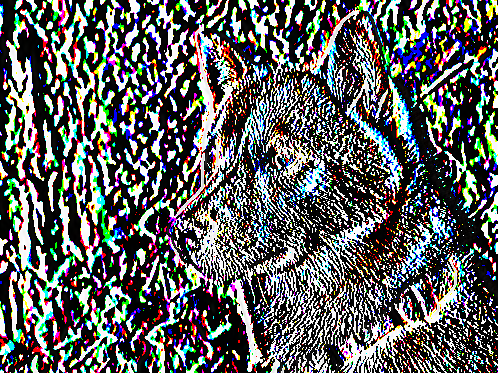

In [7]:
blur_img = blur(img,kernel)
blur_img

In [21]:
blur_img.save("output.png")